# LM34 Lab — Backtesting Without Fooling Yourself

Companion notebook to **From Calculus to Kelly, LM34**. It rebuilds the module's exhibits and computational examples from E5's wealth frame, the through case's per-trade targets and wealth paths, the declared grid's daily net returns, TR23, 0050's closes and distributions, and the delisted futures ETFs. It reruns the wealth recursion, the reality checks with Romano and Wolf's stepdown, CSCV and the Kelly walk-forward, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | The protocol: R1's net path from its targets by (27.2), then all eight rules (Example 1, Exhibit 2) |
| 2 | Costs: (34.1) on every rule, the tax share, twice the costs and the financing rates (Example 2, Exhibit 3, Example 3) |
| 3 | Look-ahead: 0050's adjusted series (Example 4, Exhibit 4), the signal's own close (Example 5), problem 8 on TR23 |
| 4 | Survivorship: the six futures ETFs (Example 6, Exhibit 5), problem 10 |
| 5 | The reality check: Experiment 10 (Example 7, Exhibit 6), Hansen's SPA, Romano and Wolf's stepdown, problem 11 and the grid (Example 8) |
| 6 | CSCV on the grid (Exhibit 7, Example 9, Exhibit 8, Exhibit 9) and on 200 noise panels (Example 10) |
| 7 | The Kelly walk-forward on TR23 (problem 9) |
| 8 | Problem 12 |
| 9 | Extension: a fourth rebalancing frequency, $n=68$ |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

On FinMind's free plan, run `uv run python data/fetch_finmind.py --exclude sectors_close/ --exclude vol4_settlement/ --exclude vol6/etf_snapshot` instead, as the book's Getting Started page says. The three excluded sets come from paid datasets. This lab reads none of them: the two ETF snapshots give only Example 6's counts, 69 and 10, which part 4 quotes from the module.

`data/` then holds these files, and the notebook reads nothing outside `data/`:

- `e5_wealth.csv`: E5's wealth frame, every TR23 session after the base close of 17 January 2017 (`R` is 0 while a fund is halted, `traded` says whether it has a close).
- `rule_targets.csv` and `rule_wealth.csv`: the through case's 92 trades per rule (signal, trade, the five target exposures, exposure, one-way turnover, cost over pre-trade wealth) and the eight rules' net and gross wealth after each close, from the first trade (`data/vol5_rules.py`).
- `lm34_grid.csv`: the declared grid's 60 configurations' net returns (`data/lm34_grid.py`), columns `R1_1m` … `R8_504_6m` (rule, window, rebalancing every 1, 3 or 6 month-end signals). Its first row, 4 March 2019, is the first purchase from the cash of 1; the 1,851 rows from 5 March 2019 to 8 October 2026 are the daily net returns.
- `taiex_tr.csv`: the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`), from which TR23's 5,849 daily returns follow.
- `0050_daily_raw.csv`, `0050_dividends.csv` and `splits__2016-12-01__2026-10-08.csv`: 0050's closes and distributions, and the registered splits (0050 4-for-1 on 2025-06-18, 00673R 1 for 4 on 2025-10-22, 00674R 1 for 5 on 2026-04-22).
- `delisting__2000-01-01__2026-10-08.csv` and the six futures ETFs' price files (`00635U__…`, `00642U__…`, `00672L__…`, `00673R__…`, `00674R__…`, `00677U__…`).

**Conventions (as in the module).**

- The through case: a signal at each month's last session from the trailing 504 joint dates of the estimation frame, a trade at the close of the next session on which every fund trades; commission 0.1425% each side, tax 0.1% on sales (0 for 00679B), cash at 1.5% a year and borrowing at 3.5%, accrued per session over $A_{\mathrm w}$; no final sale.
- Growth is $\ln W_{\text{end}}$ over the years, calendar days / 365.25 from the close before the first return. Turnover sums the one-way turnovers after the first purchase per year; costs sum cost over pre-trade wealth.
- Quantiles and medians use `method="inverted_cdf"`; counts against a threshold use the guard `1e-12`. Experiments create `np.random.default_rng([e, 20261011])` once, with LM21's `[10, 20261011]` for Experiment 10.

In [1]:
import math
from datetime import date
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from arch.bootstrap import StationaryBootstrap, optimal_block_length
from scipy import integrate, stats
from scipy.optimize import brentq

DATA = Path("data")
EPS, SEED, B = 1e-12, 20261011, 10_000
RF, SPREAD, COMMISSION = 0.015, 0.02, 0.001425
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
TAX = np.array([0.001, 0.001, 0.0, 0.001, 0.001])      # tax on sales; 00679B, a bond ETF, is exempt
RULES = [f"R{k}" for k in range(1, 9)]
pl.Config.set_tbl_rows(70)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def years(d0, d1):
    return (date.fromisoformat(d1) - date.fromisoformat(d0)).days / 365.25


def rng(e):
    return np.random.default_rng([e, SEED])


def stationary_idx(g, T, ell):
    # LM22's stationary bootstrap indices, drawn in arch's order
    start = g.integers(T, size=T)
    new = g.random(T) <= 1 / ell
    new[0] = True
    first = np.flatnonzero(new)
    blk = np.cumsum(new) - 1
    step = np.arange(T) - first[blk]
    return (start[first][blk] + step) % T


def pw(x):
    # LM22's rule before rounding: Politis and White's stationary length of the squared demeaned series
    return float(optimal_block_length((x - x.mean()) ** 2)["stationary"].iloc[0])

## Part 1 — The protocol: the wealth recursion from the targets

`rule_targets.csv` holds, for each rule, the exposures set at each of the 92 trades. Between trades each holding earns its fund's return and the cash its rate; at a trade the post-trade wealth solves (27.2), $W_t=W^{\mathrm{pre}}_t-\operatorname{cost}(W_t\mathbf f_t-W^{\mathrm{pre}}_t\mathbf w^{\mathrm{drift}}_t)$, by fixed-point iteration. The function below is the whole protocol; it must reproduce `rule_wealth.csv`.

In [2]:
wl = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides={"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8})
wf = wl.pivot(on="fund", index="date", values="R").sort("date").select("date", *FUNDS)
wd = wf["date"].to_list()
WR = wf.select(FUNDS).to_numpy()
A_w = len(wd) / years(wl["base"][0], wd[-1])
show("A_w", A_w, ".2f", "243.57")
tg = pl.read_csv(DATA / "rule_targets.csv", schema_overrides={"signal": pl.Utf8, "trade": pl.Utf8})
rw = pl.read_csv(DATA / "rule_wealth.csv", schema_overrides={"date": pl.Utf8}).sort("rule", "date")


def targets(rule):
    t = tg.filter(pl.col("rule") == pl.lit(rule)).sort("trade")
    return t["signal"].to_list(), t["trade"].to_list(), t.select(FUNDS).to_numpy()


def path(tgt, first, cost_mult=1.0, spread=SPREAD, rf=RF, tax=TAX):
    # (27.2) from the cash of 1 at the close of `first`; tgt: trade date -> exposures. Returns the wealth after each
    # close from `first` and each trade's cost over pre-trade wealth.
    i0 = wd.index(first)
    h, c, out, costs = np.zeros(5), 1.0, [], []
    for i in range(i0, len(wd)):
        if i > i0:
            h = h * (1 + WR[i])
            c *= 1 + (rf if c >= 0 else rf + spread) / A_w
        W = h.sum() + c
        f = tgt.get(wd[i])
        if f is not None:
            Wn = W
            for _ in range(100):
                d = Wn * f - h
                cost = cost_mult * (COMMISSION * np.abs(d).sum() + tax @ np.clip(-d, 0, None))
                if abs(W - cost - Wn) < 1e-15 * W:
                    break
                Wn = W - cost
            costs.append(cost / W)
            h, c, W = Wn * f, Wn * (1 - f.sum()), Wn
        out.append(W)
    return np.array(out), np.array(costs)


sig, trd, F = targets("R1")
first = trd[0]
tau = years(first, wd[-1])
show("tau (years from the close of 4 March 2019)", tau, ".4f", "7.5975")
net1, _ = path(dict(zip(trd, F)), first)
ref1 = rw.filter(pl.col("rule") == pl.lit("R1"))
assert ref1["date"].to_list() == wd[wd.index(first):]
print(f"R1 rebuilt against rule_wealth.csv: largest gap {np.abs(net1 - ref1['wealth'].to_numpy()).max():.1e}")
assert np.abs(net1 - ref1["wealth"].to_numpy()).max() < 1e-12

A_w: 243.57   [book: 243.57]
tau (years from the close of 4 March 2019): 7.5975   [book: 7.5975]
R1 rebuilt against rule_wealth.csv: largest gap 0.0e+00


The same function now rebuilds all eight rules, net and gross, and Example 1's table.

rule   wealth  growth %  gross %  turnover  costs %
R1     2.6620     12.89    12.99      0.24     0.81
R2     3.0079     14.49    14.58      0.18     0.64
R3     1.9367      8.70     8.85      0.35     1.12
R4     2.2214     10.51    11.06      1.45     4.22
R5     2.0400      9.38     9.52      0.32     1.03
R6     2.2722     10.80    10.91      0.24     0.81
R7     2.1829     10.28    10.44      0.41     1.28
R8     2.4119     11.59    11.99      1.10     3.06
R1 growth from the printed wealth: 12.89   [book: 12.89]
R2 wealth: 3.0079   [book: 3.0079]
R2 growth: 14.49   [book: 14.49]
R4 turnover a year: 1.45   [book: 1.45]
ranking: R2 > R1 > R8 > R6 > R4 > R7 > R5 > R3


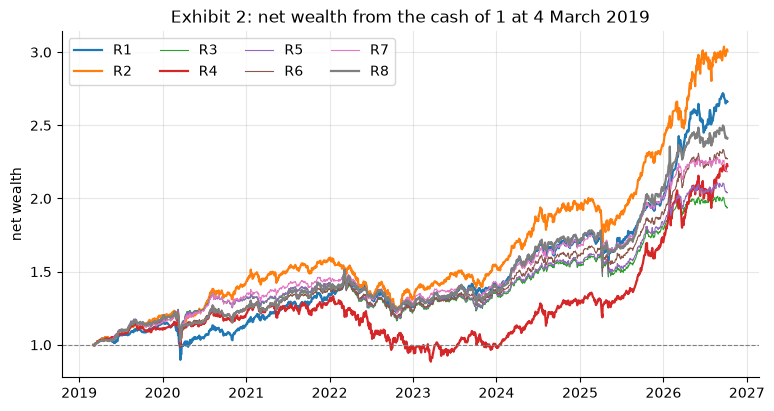

In [3]:
NET, GROSS, COSTS, TGT = {}, {}, {}, {}
for k in RULES:
    s_, t_, F_ = targets(k)
    TGT[k] = (s_, t_, F_)
    NET[k], COSTS[k] = path(dict(zip(t_, F_)), first)
    GROSS[k], _ = path(dict(zip(t_, F_)), first, cost_mult=0.0)
    ref = rw.filter(pl.col("rule") == pl.lit(k))
    assert np.abs(NET[k] - ref["wealth"].to_numpy()).max() < 1e-12
    assert np.abs(GROSS[k] - ref["wealth_gross"].to_numpy()).max() < 1e-12
growth = {k: math.log(NET[k][-1]) / tau for k in RULES}
gross_g = {k: math.log(GROSS[k][-1]) / tau for k in RULES}
turn = {k: tg.filter(pl.col("rule") == pl.lit(k)).sort("trade")["turnover"][1:].sum() / tau for k in RULES}
table = pl.DataFrame({"rule": RULES, "wealth": [NET[k][-1] for k in RULES],
                      "growth %": [100 * growth[k] for k in RULES],
                      "gross %": [100 * gross_g[k] for k in RULES],
                      "turnover": [turn[k] for k in RULES],
                      "costs %": [100 * COSTS[k].sum() for k in RULES]})
print(f"{'rule':<5}{'wealth':>8}{'growth %':>10}{'gross %':>9}{'turnover':>10}{'costs %':>9}")
for r in table.iter_rows(named=True):              # the module's digits: wealth 4 decimals, the rest 2
    print(f"{r['rule']:<5}{r['wealth']:>8.4f}{r['growth %']:>10.2f}{r['gross %']:>9.2f}{r['turnover']:>10.2f}"
          f"{r['costs %']:>9.2f}")
show("R1 growth from the printed wealth", 100 * math.log(2.6620) / 7.5975, ".2f", "12.89")
show("R2 wealth", NET["R2"][-1], ".4f", "3.0079")
show("R2 growth", 100 * growth["R2"], ".2f", "14.49")
show("R4 turnover a year", turn["R4"], ".2f", "1.45")
print("ranking:", " > ".join(sorted(RULES, key=lambda k: -growth[k])))
fig, ax = plt.subplots()
x = np.array(wd[wd.index(first):], dtype="datetime64[D]")
for k in RULES:
    ax.plot(x, NET[k], lw=1.6 if k in ("R1", "R2", "R4", "R8") else 0.8, label=k)
ax.axhline(1, ls="--", lw=0.8, color="grey")
ax.set_ylabel("net wealth")
ax.set_title("Exhibit 2: net wealth from the cash of 1 at 4 March 2019")
ax.legend(ncol=4)
plt.show()

## Part 2 — Costs and (34.1)

By (34.1) the log gap between gross and net wealth is $-\sum\ln(1-\operatorname{cost}/W^{\mathrm{pre}})$, at least the sum of the cost shares. The tax share comes from rerunning with every tax at 0; twice the costs, the borrowing spreads and R8's risk-free rate are reruns of the same function (R4's targets change with $r_f$, so its two other rates need `vol5_rules.py` and are not rebuilt here).

R1 log gap: 0.0080768   [book: 0.0080768]
R1 cost sum: 0.0080755   [book: 0.0080755]
R4 log gap: 0.0422296   [book: 0.0422296]
R4 cost sum: 0.0422153   [book: 0.0422153]
tax share, lowest: 17   [book: 17]
tax share, highest: 22   [book: 22]
R4 at twice the costs: 9.95   [book: 9.95]
R1 at twice the costs: 12.78   [book: 12.78]
ranking at twice the costs: R2 > R1 > R8 > R6 > R7 > R4 > R5 > R3
R8 at a spread of 0.00: 11.99   [book: 11.99]
R8 at a spread of 0.02: 11.59   [book: 11.59]
R8 at a spread of 0.05: 10.99   [book: 10.99]
R8 at r_f = 0: 11.79   [book: 11.79]
R8 at r_f = 0.02: 11.52   [book: 11.52]


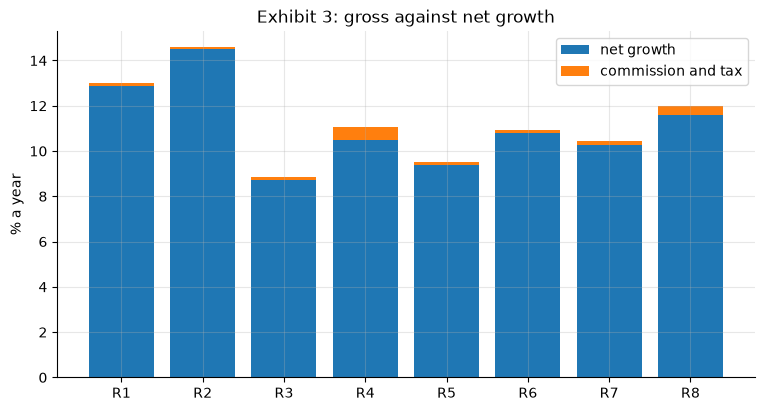

In [4]:
for k in RULES:
    gap = math.log(GROSS[k][-1] / NET[k][-1])
    assert abs(gap + np.log1p(-COSTS[k]).sum()) < 2e-14 and gap > COSTS[k].sum()
show("R1 log gap", math.log(GROSS["R1"][-1] / NET["R1"][-1]), ".7f", "0.0080768")
show("R1 cost sum", COSTS["R1"].sum(), ".7f", "0.0080755")
show("R4 log gap", math.log(GROSS["R4"][-1] / NET["R4"][-1]), ".7f", "0.0422296")
show("R4 cost sum", COSTS["R4"].sum(), ".7f", "0.0422153")
share = {}
for k in RULES:
    s_, t_, F_ = TGT[k]
    _, cc = path(dict(zip(t_, F_)), first, tax=np.zeros(5))
    share[k] = 1 - cc.sum() / COSTS[k].sum()
show("tax share, lowest", 100 * min(share.values()), ".0f", "17")
show("tax share, highest", 100 * max(share.values()), ".0f", "22")
twice = {}
for k in RULES:
    s_, t_, F_ = TGT[k]
    twice[k] = math.log(path(dict(zip(t_, F_)), first, cost_mult=2.0)[0][-1]) / tau
show("R4 at twice the costs", 100 * twice["R4"], ".2f", "9.95")
show("R1 at twice the costs", 100 * twice["R1"], ".2f", "12.78")
print("ranking at twice the costs:", " > ".join(sorted(RULES, key=lambda k: -twice[k])))
s8, t8, F8 = TGT["R8"]
for spread, printed in ((0.0, "11.99"), (SPREAD, "11.59"), (0.05, "10.99")):
    show(f"R8 at a spread of {spread:.2f}", 100 * math.log(path(dict(zip(t8, F8)), first, spread=spread)[0][-1]) / tau,
         ".2f", printed)
for rf, printed in ((0.0, "11.79"), (0.02, "11.52")):
    show(f"R8 at r_f = {rf:g}", 100 * math.log(path(dict(zip(t8, F8)), first, rf=rf)[0][-1]) / tau, ".2f", printed)
fig, ax = plt.subplots()
ax.bar(RULES, [100 * growth[k] for k in RULES], label="net growth")
ax.bar(RULES, [100 * (gross_g[k] - growth[k]) for k in RULES], bottom=[100 * growth[k] for k in RULES],
       label="commission and tax")
ax.set_ylabel("% a year")
ax.set_title("Exhibit 3: gross against net growth")
ax.legend()
plt.show()

## Part 3 — Look-ahead

**Adjusted prices.** (34.2) compounds Volume I's total returns, $(P_t+D_t)/P_{t-1}-1$, with the previous close restated per current share on a split day (0050 divided by 4 on 2025-06-18). An adjusted close of day $t$ in a series built on day $t'$ is the close of $t'$ over the growth factor from $t$ to $t'$.

In [5]:
px = pl.read_csv(DATA / "0050_daily_raw.csv", schema_overrides={"date": pl.Utf8}).sort("date")
dv = pl.read_csv(DATA / "0050_dividends.csv", schema_overrides={"date": pl.Utf8})
sp = pl.read_csv(DATA / "splits__2016-12-01__2026-10-08.csv", schema_overrides={"date": pl.Utf8, "stock_id": pl.Utf8})
d50 = px["date"].to_list()
c50 = px["close"].to_numpy()
div = dict(zip(dv["date"].to_list(), dv["cash_dividend"].to_list()))
s50 = sp.filter(pl.col("stock_id") == pl.lit("0050"))
split = {d: round(b / a) for d, b, a in zip(s50["date"], s50["before_price"], s50["after_price"])}
assert split == {"2025-06-18": 4}
R50 = np.array([1.0] + [(c50[i] + div.get(d50[i], 0.0)) / (c50[i - 1] / split.get(d50[i], 1))
                        for i in range(1, len(c50))])
cum = np.cumprod(R50)


def adj(at, built):
    i, j = d50.index(at), d50.index(built)
    return c50[j] / (cum[j] / cum[i])


show("close of 17 January 2017", c50[d50.index("2017-01-17")], ".2f", "72.30")
for built, printed in (("2020-01-02", "65.12"), ("2024-12-31", "55.20"), ("2026-10-08", "13.25")):
    show(f"adjusted close of 17 January 2017, built {built}", adj("2017-01-17", built), ".2f", printed)
show("distributions after 17 January 2017", sum(1 for d in div if "2017-01-17" < d <= "2026-10-08"), "d", "20")
ex17 = sorted(d for d in div if d.startswith("2017"))
for d, a, b in zip(ex17, ("2.32", "0.85"), ("12.65", "4.54")):
    prev = d50[d50.index(d) - 1]
    show(f"{d} yield on the previous close", 100 * div[d] / c50[d50.index(prev)], ".2f", a)
    show(f"{d} yield on the 2026 series", 100 * div[d] / adj(prev, "2026-10-08"), ".2f", b)
end17 = max(d for d in d50 if d.startswith("2017"))
show("2017 yield, actual", 100 * sum(div[d] for d in ex17) / c50[d50.index(end17)], ".2f", "2.92")
show("2017 yield, 2026 series", 100 * sum(div[d] for d in ex17) / adj(end17, "2026-10-08"), ".2f", "15.44")

close of 17 January 2017: 72.30   [book: 72.30]
adjusted close of 17 January 2017, built 2020-01-02: 65.12   [book: 65.12]
adjusted close of 17 January 2017, built 2024-12-31: 55.20   [book: 55.20]
adjusted close of 17 January 2017, built 2026-10-08: 13.25   [book: 13.25]
distributions after 17 January 2017: 20   [book: 20]
2017-02-08 yield on the previous close: 2.32   [book: 2.32]
2017-02-08 yield on the 2026 series: 12.65   [book: 12.65]
2017-07-31 yield on the previous close: 0.85   [book: 0.85]
2017-07-31 yield on the 2026 series: 4.54   [book: 4.54]
2017 yield, actual: 2.92   [book: 2.92]
2017 yield, 2026 series: 15.44   [book: 15.44]


**The signal's own close** (Example 5, *look-ahead, not achievable*): the 91 later trades move to their signal day's close; the first purchase stays on 4 March 2019.

In [6]:
same = {}
for k in RULES:
    s_, t_, F_ = TGT[k]
    early = {t_[0]: F_[0], **{s: f for s, f in zip(s_[1:], F_[1:])}}
    same[k] = math.log(path(early, first)[0][-1]) / tau
for k, printed in (("R1", "13.14"), ("R2", "14.59"), ("R4", "10.09"), ("R8", "12.48")):
    show(f"{k} at the signal's close", 100 * same[k], ".2f", printed)
chg = {k: 100 * (same[k] - growth[k]) for k in RULES}
show("lowest change (R4)", min(chg.values()), ".2f", "-0.41")
show("highest change (R8)", max(chg.values()), ".2f", "0.89")
show("R1's change (no estimate: the shift alone)", chg["R1"], "+.2f", "+0.26")
show("R2's change (no estimate: the shift alone)", chg["R2"], "+.2f", "+0.09")
print("rules that gain:", sum(v > 0 for v in chg.values()), "of 8")

R1 at the signal's close: 13.14   [book: 13.14]
R2 at the signal's close: 14.59   [book: 14.59]
R4 at the signal's close: 10.09   [book: 10.09]
R8 at the signal's close: 12.48   [book: 12.48]
lowest change (R4): -0.41   [book: -0.41]
highest change (R8): 0.89   [book: 0.89]
R1's change (no estimate: the shift alone): +0.26   [book: +0.26]
R2's change (no estimate: the shift alone): +0.09   [book: +0.09]
rules that gain: 7 of 8


**Problem 8.** R8's scale (31.7) on TR23's daily simple returns: $\bar\sigma_t^2$ the uncentred mean square of the 504 returns through $t$, and (26.2) with $\lambda=0.94$ run through the same returns from $\bar\sigma_t^2$. Set at the close of $t$ and traded at the next close, it first scales $R_{t+2}$; the version that peeks scales $R_t$ itself; the scale traded at its own close, as in Example 5, scales $R_{t+1}$. All three run on the honest version's days, with cash and borrowing at 0.

In [7]:
tr = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"date": pl.Utf8}).sort("date")
TD = tr["date"].to_list()[1:]
R = tr["price"].to_numpy()[1:] / tr["price"].to_numpy()[:-1] - 1
T = len(R)
show("TR23 returns", T, ",d", "5,849")
W, lam = 504, 0.94
sq = np.lib.stride_tricks.sliding_window_view(R**2, W)
sbar2 = np.full(T, np.nan)
sbar2[W - 1:] = sq.mean(axis=1)
ew = np.full(T, np.nan)                        # the EWMA run through each window, in closed form
ew[W - 1:] = lam**W * sbar2[W - 1:] + sq @ ((1 - lam) * lam ** np.arange(W - 1, -1, -1))
scale = np.minimum(1.5, np.sqrt(sbar2 / ew))   # known at the close of t
honest, own, peek = (np.full(T, np.nan) for _ in range(3))
honest[W + 1:] = scale[W - 1:-2]
own[W:] = scale[W - 1:-1]                      # traded at the close it is set
peek[W:] = scale[W:]
ok = ~np.isnan(honest)
assert int(np.flatnonzero(ok)[0]) == W + 1     # a scale set at the close of t first scales R at t + 2
yrs = years(TD[W], TD[-1])
A = ok.sum() / yrs
show("days", int(ok.sum()), ",d", "5,344")
show("years", yrs, ".2f", "21.74")
show("A", A, ".2f", "245.83")


def run(lv):
    x = lv[ok] * R[ok]
    return np.log1p(x).sum() / yrs, x.std() * math.sqrt(A), x.min()


for lab, lv, pr in (("traded at the next close", honest, ("15.08", "18.27", "-7.50")),
                    ("with the same day's return", peek, ("16.70", "17.04", "-4.93"))):
    g, v, m = run(lv)
    show(f"{lab}: growth", 100 * g, ".2f", pr[0])
    show(f"{lab}: volatility", 100 * v, ".2f", pr[1])
    show(f"{lab}: worst day", 100 * m, ".2f", pr[2])
show("traded at its own close: growth", 100 * run(own)[0], ".2f", "14.90")
i7 = TD.index("2025-04-07")
show("7 April 2025: honest scale", honest[i7], ".3f", "0.703")
show("7 April 2025: peeking scale", peek[i7], ".3f", "0.428")
show("7 April 2025: honest scaled return, %", 100 * honest[i7] * R[i7], ".2f", "-6.81")
show("7 April 2025: peeking scaled return, %", 100 * peek[i7] * R[i7], ".2f", "-4.15")
print(f"from the printed inputs: 9.70 x 0.703 = {9.70 * 0.703:.2f}, so the module's -6.81 uses unrounded values")
show("TR23 itself: growth", 100 * np.log1p(R[ok]).sum() / yrs, ".2f", "13.32")

TR23 returns: 5,849   [book: 5,849]
days: 5,344   [book: 5,344]
years: 21.74   [book: 21.74]
A: 245.83   [book: 245.83]
traded at the next close: growth: 15.08   [book: 15.08]
traded at the next close: volatility: 18.27   [book: 18.27]
traded at the next close: worst day: -7.50   [book: -7.50]
with the same day's return: growth: 16.70   [book: 16.70]
with the same day's return: volatility: 17.04   [book: 17.04]
with the same day's return: worst day: -4.93   [book: -4.93]
traded at its own close: growth: 14.90   [book: 14.90]
7 April 2025: honest scale: 0.703   [book: 0.703]
7 April 2025: peeking scale: 0.428   [book: 0.428]
7 April 2025: honest scaled return, %: -6.81   [book: -6.81]
7 April 2025: peeking scaled return, %: -4.15   [book: -4.15]
from the printed inputs: 9.70 x 0.703 = 6.82, so the module's -6.81 uses unrounded values
TR23 itself: growth: 13.32   [book: 13.32]


## Part 4 — Survivorship

Each fund's growth factor runs from its close of 17 January 2017 to its last traded close on or before 8 October 2026. Untraded rows (close 0) are skipped, a zero spread is accepted only on the first traded row after an untraded one, every other close must equal the previous traded close plus the spread, and the two reverse splits restate the previous close per current unit. A delisted fund's last close is kept as cash. The ETF counts of Example 6, 69 and 10, come from two FinMind snapshots that are not lab files.

00635U (to 2026-10-08): 2.198   [book: 2.198]
00642U (to 2026-10-08): 1.593   [book: 1.593]
00672L (to 2020-11-12, delisted 2020-11-13): 0.038   [book: 0.038]
00673R (to 2026-10-08): 0.140   [book: 0.140]
00674R (to 2026-10-08): 0.285   [book: 0.285]
00677U (to 2021-06-02, delisted 2021-06-03): 0.086   [book: 0.086]
all six: 0.7234   [book: 0.7234]
the four survivors: 1.0539   [book: 1.0539]
gap in log growth, points a year: 3.87   [book: 3.87]
problem 10: mean of the printed factors: 0.7233   [book: 0.7233]
problem 10: survivors' printed mean: 1.0540   [book: 1.0540]
problem 10: gap: 3.87   [book: 3.87]


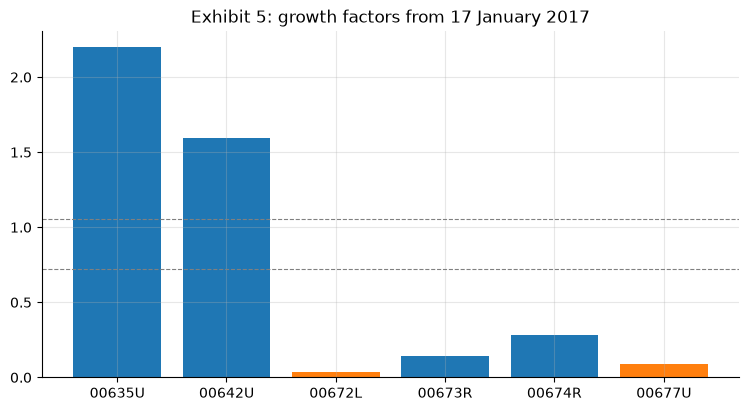

In [8]:
SIX = ["00635U", "00642U", "00672L", "00673R", "00674R", "00677U"]
dl = pl.read_csv(DATA / "delisting__2000-01-01__2026-10-08.csv", schema_overrides={"date": pl.Utf8, "stock_id": pl.Utf8})
gone = dict(zip(dl["stock_id"], dl["date"]))


def factor(sym):
    p = (pl.read_csv(DATA / f"{sym}__2016-12-01__2026-10-08.csv", schema_overrides={"date": pl.Utf8})
         .filter(pl.col("date").is_between(pl.lit("2017-01-17"), pl.lit("2026-10-08"))).sort("date"))
    s = sp.filter(pl.col("stock_id") == pl.lit(sym))
    rows = p.select("date", "close", "spread").rows()
    g, prev, idle, last = 1.0, rows[0][1], False, rows[0][0]
    for d, c, spr in rows[1:]:
        if c == 0:
            idle = True
            continue
        if d in s["date"].to_list():
            b, a = s.filter(pl.col("date") == pl.lit(d)).select("before_price", "after_price").row(0)
            g *= c / (prev / (b / a))            # b / a = 1/4 or 1/5 for these reverse splits
        else:
            assert abs(c - prev - spr) < 1e-9 or (spr == 0 and idle), (sym, d)
            g *= c / prev
        prev, idle, last = c, False, d
    return g, last


G6 = {s: factor(s) for s in SIX}
for s, pr in zip(SIX, ("2.198", "1.593", "0.038", "0.140", "0.285", "0.086")):
    show(f"{s} (to {G6[s][1]}{', delisted ' + gone[s] if s in gone else ''})", G6[s][0], ".3f", pr)
all6 = np.mean([G6[s][0] for s in SIX])
sur = np.mean([G6[s][0] for s in SIX if s not in gone])
y17 = years("2017-01-17", "2026-10-08")
show("all six", all6, ".4f", "0.7234")
show("the four survivors", sur, ".4f", "1.0539")
show("gap in log growth, points a year", 100 * (math.log(sur) - math.log(all6)) / y17, ".2f", "3.87")
p6 = np.mean([round(G6[s][0], 3) for s in SIX])
p4 = np.mean([round(G6[s][0], 3) for s in SIX if s not in gone])
show("problem 10: mean of the printed factors", p6, ".4f", "0.7233")
show("problem 10: survivors' printed mean", p4, ".4f", "1.0540")
show("problem 10: gap", 100 * math.log(p4 / p6) / y17, ".2f", "3.87")
fig, ax = plt.subplots()
ax.bar(SIX, [G6[s][0] for s in SIX], color=["C1" if s in gone else "C0" for s in SIX])
for v in (all6, sur):
    ax.axhline(v, ls="--", lw=0.8, color="grey")
ax.set_title("Exhibit 5: growth factors from 17 January 2017")
plt.show()

## Part 5 — The reality check

**Experiment 10** (LM21): 10,000 random long–short rules on TR23 from `default_rng([10, 20261011])`. The reality check (experiment 1) resamples the days with LM22's `stationary_idx` at $\ell=145$, which first is checked against arch's `StationaryBootstrap`; each resample is a vector of day counts, so the resampled means of all rules are one matrix product. The studentized form divides by each rule's sample $s_{\mathrm u}$ (Romano and Wolf's footnote 22); Hansen's SPA recentres only the rules with a t-stat of at least $-\sqrt{2\ln\ln T}$. Romano and Wolf's stepdown starts from the bootstrap 95% point of the largest centred t-stat: with the sample's $s_{\mathrm u}$ inside the resamples (their Algorithm 4.1 with footnote 22's variant) and with each resample's own $s_{\mathrm u}$ (Algorithm 4.2), which is cheap here because every rule's squared return is $R_t^2$.

In [9]:
g1, g2 = rng(30), rng(30)                     # experiment 30: twin generators, an index check only
bs = StationaryBootstrap(145, R, seed=g1)
assert all(np.array_equal(bs.index, stationary_idx(g2, T, 145)) for _ in bs.bootstrap(3))
M = 10_000
pos = rng(10).integers(0, 2, size=(M, T), dtype=np.int8)     # LM21's generator, default_rng([10, 20261011])
dbar, s_u = np.empty(M), np.empty(M)
for c0 in range(0, M, 500):
    x = (2.0 * pos[c0:c0 + 500] - 1.0) * R
    dbar[c0:c0 + 500], s_u[c0:c0 + 500] = x.mean(axis=1), x.std(axis=1, ddof=1)
tt = dbar / (s_u / math.sqrt(T))
best = int(np.argmax(tt))
show("best t-stat", tt[best], ".4f", "3.9738")
print("rule", best + 1)
p1 = stats.norm.sf(tt[best])
show("Bonferroni", M * p1, ".3f", "0.354")
show("(21.9)", 1 - stats.norm.cdf(tt[best]) ** M, ".3f", "0.298")
ells = np.array([pw((2.0 * pos[k] - 1.0) * R) for k in range(M)])
show("LM22's rule: the largest estimate", ells.max(), ".2f", "145.44")
ell = round(ells.max())

best t-stat: 3.9738   [book: 3.9738]
rule 7840
Bonferroni: 0.354   [book: 0.354]
(21.9): 0.298   [book: 0.298]
LM22's rule: the largest estimate: 145.44   [book: 145.44]


White's p-value: 0.283   [book: 0.283]
studentized: 0.281   [book: 0.281]
its MC SE: 0.0045   [book: 0.0045]
Hansen's SPA: 0.277   [book: 0.277]
rules recentred: 9,814   [book: 9,814]
bootstrap 95% point (Algorithm 4.1's first step): 4.77   [book: 4.77]
Romano and Wolf's stepdown: Algorithm 4.1 rejects 0 rules at step 1 (95% point 4.771); Algorithm 4.2, each resample's own SE, rejects 0 (95% point 4.719). With nothing rejected, the stepdown stops after its first step.


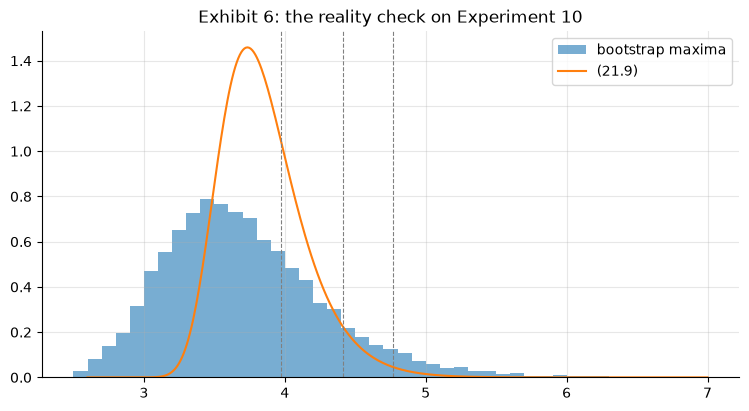

In [10]:
g = rng(1)
thr = math.sqrt(2 * math.log(math.log(T)))
keep = tt >= -thr
mw, mt, mc, m42 = (np.empty(B) for _ in range(4))
R2s = R**2
for b0 in range(0, B, 1000):
    Cn = np.stack([np.bincount(stationary_idx(g, T, ell), minlength=T) for _ in range(1000)], axis=1)
    RC = R[:, None] * Cn / T
    sq = (R2s @ Cn) / T                          # every rule's resampled mean square (f^2 = 1)
    w_, t_, c_, z2 = (np.full(1000, -np.inf) for _ in range(4))
    for r0 in range(0, M, 2000):
        Db = (2.0 * pos[r0:r0 + 2000] - 1.0) @ RC
        se = s_u[r0:r0 + 2000, None] / math.sqrt(T)
        dc = Db - dbar[r0:r0 + 2000, None]
        w_ = np.maximum(w_, math.sqrt(T) * dc.max(axis=0))
        t_ = np.maximum(t_, (dc / se).max(axis=0))
        c_ = np.maximum(c_, np.where(keep[r0:r0 + 2000, None], dc / se, Db / se).max(axis=0))
        own = np.sqrt((sq - Db**2) * T / (T - 1)) / math.sqrt(T)   # each resample's own SE (Algorithm 4.2)
        z2 = np.maximum(z2, (dc / own).max(axis=0))
    mw[b0:b0 + 1000], mt[b0:b0 + 1000], mc[b0:b0 + 1000], m42[b0:b0 + 1000] = w_, t_, c_, z2
p_white = (mw >= math.sqrt(T) * dbar.max() - EPS).mean()
p_stud = (mt >= tt[best] - EPS).mean()
p_spa = (np.maximum(mc, 0) >= max(tt[best], 0) - EPS).mean()
show("White's p-value", p_white, ".3f", "0.283")
show("studentized", p_stud, ".3f", "0.281")
show("its MC SE", math.sqrt(p_stud * (1 - p_stud) / B), ".4f", "0.0045")
show("Hansen's SPA", p_spa, ".3f", "0.277")
show("rules recentred", int(keep.sum()), ",d", "9,814")
q41 = np.quantile(mt, 0.95, method="inverted_cdf")
q42 = np.quantile(m42, 0.95, method="inverted_cdf")
show("bootstrap 95% point (Algorithm 4.1's first step)", q41, ".2f", "4.77")
print(f"Romano and Wolf's stepdown: Algorithm 4.1 rejects {(tt > q41 + EPS).sum()} rules at step 1 (95% point "
      f"{q41:.3f}); Algorithm 4.2, each resample's own SE, rejects {(tt > q42 + EPS).sum()} (95% point {q42:.3f}). "
      "With nothing rejected, the stepdown stops after its first step.")
fig, ax = plt.subplots()
ax.hist(mt, bins=np.arange(2.5, 7.01, 0.1), density=True, alpha=0.6, label="bootstrap maxima")
zz = np.linspace(2.6, 7, 400)
ax.plot(zz, M * stats.norm.pdf(zz) * stats.norm.cdf(zz) ** (M - 1), label="(21.9)")
for v in (tt[best], q41, stats.norm.ppf(0.95 ** (1 / M))):
    ax.axvline(v, ls="--", lw=0.8, color="grey")
ax.set_title("Exhibit 6: the reality check on Experiment 10")
ax.legend()
plt.show()

**Problem 11 and Example 8**: the studentized check of the grid's 59 differences from R1 monthly, with the block length of LM22's rule on those differences (experiment 4) and at R1 monthly's own length, 17 (experiment 5). LM22's rule takes the largest length, since one resample moves every series together.

In [11]:
gd = pl.read_csv(DATA / "lm34_grid.csv", schema_overrides={"date": pl.Utf8}).sort("date")
assert gd["date"].to_list() == wd[wd.index(first):]
names = gd.columns[1:]
XF = gd.select(names).to_numpy()                 # row 0: the first purchase from the cash of 1
X = XF[1:]                                       # the 1,851 daily net returns
assert X.shape == (1851, 60)
for k in RULES:                                  # the through case's eight are configurations of the grid
    col = f"{k}_1m" if k in ("R1", "R2") else f"{k}_504_1m"
    assert np.abs(XF[:, names.index(col)] - np.diff(NET[k], prepend=1.0) / np.r_[1.0, NET[k][:-1]]).max() < 1e-12
D = np.delete(X, names.index("R1_1m"), axis=1) - X[:, [names.index("R1_1m")]]
Tg = len(D)
dm, se = D.mean(axis=0), D.std(axis=0, ddof=1) / math.sqrt(Tg)
tg_ = dm / se
others = [n for n in names if n != "R1_1m"]
show("largest t-stat", tg_.max(), ".3f", "1.296")
print("at", others[int(np.argmax(tg_))])
ests = [pw(D[:, j]) for j in range(D.shape[1])]
show("LM22's rule on the 59 differences", max(ests), ".2f", "74.63")
show("R1 monthly's own estimate", pw(X[:, names.index("R1_1m")]), ".0f", "17")


def reality_check(d, ell, B, g):
    T = len(d)
    dm, se = d.mean(0), d.std(0, ddof=1) / np.sqrt(T)
    mx = np.empty(B)
    for b in range(B):
        c = np.bincount(stationary_idx(g, T, ell), minlength=T)
        mx[b] = ((c @ d / T - dm) / se).max()
    return (mx >= (dm / se).max() - EPS).mean(), mx


p75, mx75 = reality_check(D, round(max(ests)), B, rng(4))
p17, _ = reality_check(D, 17, B, rng(5))
show("reality check at 75", p75, ".3f", "0.375")
show("reality check at 17", p17, ".3f", "0.421")
show("bootstrap 95% point", np.quantile(mx75, 0.95, method="inverted_cdf"), ".2f", "2.42")
show("Bonferroni's", stats.norm.isf(0.05 / 59), ".2f", "3.14")
cc = np.corrcoef(D, rowvar=False)[np.triu_indices(59, 1)]
show("median correlation", np.quantile(cc, 0.5, method="inverted_cdf"), ".2f", "0.78")

largest t-stat: 1.296   [book: 1.296]
at R4_126_6m
LM22's rule on the 59 differences: 74.63   [book: 74.63]
R1 monthly's own estimate: 17   [book: 17]
reality check at 75: 0.375   [book: 0.375]
reality check at 17: 0.421   [book: 0.421]
bootstrap 95% point: 2.42   [book: 2.42]
Bonferroni's: 3.14   [book: 3.14]
median correlation: 0.78   [book: 0.78]


## Part 6 — CSCV

The module's `cscv` (Section 9): block sums, every choice of 8 of the 16 blocks, one matrix product for the in-sample sums, and the out-of-sample sums as the totals minus those. The performance is the Sharpe ratio of daily returns in excess of $r_f/A_{\mathrm w}$.

the highest bump: 18.62   [book: 18.62]
best R4_252_6m
median (inverted_cdf, the 30th of 60): 10.96   [book: 10.96]
worst: 7.60   [book: 7.60]
splits: 12,870   [book: 12,870]
PBO: 0.663   [book: 0.663]
logit median: -0.72   [book: -0.72]
out-of-sample ratio below 0, % of splits: 0.99   [book: 0.99]
degradation slope: -0.86   [book: -0.86]
most frequent in-sample bests: R2_1m 0.191, R4_252_6m 0.188, R4_126_6m 0.138 | distinct 31


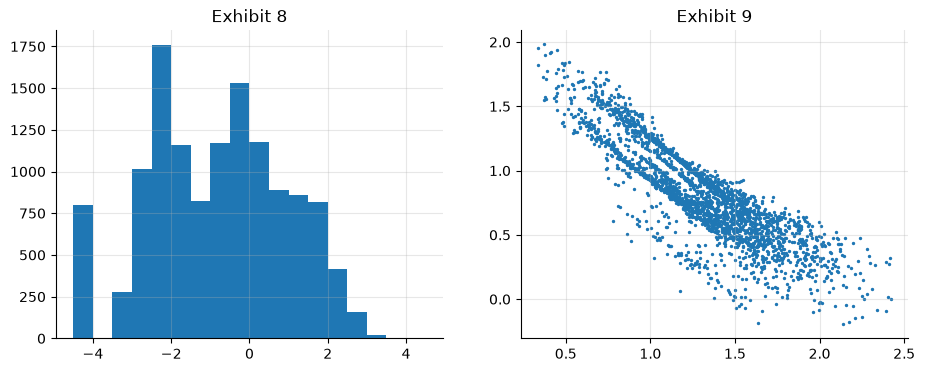

In [12]:
def cscv(x, S=16):
    T, n = x.shape
    m = T // S
    blk = x[T - m * S:].reshape(S, m, n)
    s1, s2 = blk.sum(1), (blk**2).sum(1)
    cmb = list(combinations(range(S), S // 2))
    mask = np.zeros((len(cmb), S))
    for r, c in enumerate(cmb):
        mask[r, list(c)] = 1.0
    h = m * (S // 2)
    i1, i2 = mask @ s1, mask @ s2
    o1, o2 = s1.sum(0) - i1, s2.sum(0) - i2
    sr_i = i1 / h / np.sqrt(i2 / h - (i1 / h) ** 2)
    sr_o = o1 / h / np.sqrt(o2 / h - (o1 / h) ** 2)
    best = sr_i.argmax(1)
    so = sr_o[np.arange(len(cmb)), best]
    j = 1 + (sr_o < so[:, None]).sum(1)
    w = j / (n + 1)
    return np.log(w / (1 - w)), sr_i[np.arange(len(cmb)), best], so, best


gg = np.log1p(XF).sum(axis=0) / tau             # growth from the cash of 1, the first purchase's cost included
order = np.argsort(-gg, kind="stable")
show("the highest bump", 100 * gg[order[0]], ".2f", "18.62")
print("best", names[order[0]])
show("median (inverted_cdf, the 30th of 60)", 100 * np.quantile(gg, 0.5, method="inverted_cdf"), ".2f", "10.96")
show("worst", 100 * gg[order[-1]], ".2f", "7.60")
lg, is_, oos, bst = cscv(X - RF / A_w)
show("splits", len(lg), ",d", "12,870")
show("PBO", (lg <= EPS).mean(), ".3f", "0.663")
show("logit median", np.quantile(lg, 0.5, method="inverted_cdf"), ".2f", "-0.72")
show("out-of-sample ratio below 0, % of splits", 100 * (oos < 0).mean(), ".2f", "0.99")
sl, ic = np.polyfit(is_ * math.sqrt(A_w), oos * math.sqrt(A_w), 1)
show("degradation slope", sl, ".2f", "-0.86")
cnt = np.bincount(bst, minlength=60)
print("most frequent in-sample bests:", ", ".join(f"{names[i]} {cnt[i] / len(lg):.3f}" for i in np.argsort(-cnt)[:3]),
      f"| distinct {(cnt > 0).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.clip(lg, -4.5, 4.5), bins=np.linspace(-4.5, 4.5, 19))
ax[0].set_title("Exhibit 8")
ax[1].scatter(is_[::5] * math.sqrt(A_w), oos[::5] * math.sqrt(A_w), s=2)
ax[1].set_title("Exhibit 9")
plt.show()

**Example 10** (*model*): CSCV with $r_f=0$ on 200 panels of 60 independent zero-mean strategies, each panel one draw `standard_normal((1851, 60))` × 1% from `default_rng([2, 20261011])`, rows days.

In [13]:
g = rng(2)
pb, a_is, a_oos = [], [], []
for _ in range(200):
    lg_, is_n, oos_n, _ = cscv(g.standard_normal((1851, 60)) * 0.01)
    pb.append((lg_ <= EPS).mean())
    a_is.append(is_n.mean() * math.sqrt(A_w))
    a_oos.append(oos_n.mean() * math.sqrt(A_w))
show("mean PBO", np.mean(pb), ".2f", "0.50")
show("its SE", np.std(pb) / math.sqrt(200), ".3f", "0.012")
show("lowest panel", min(pb), ".2f", "0.12")
show("highest panel", max(pb), ".2f", "0.87")
show("in-sample best, in sample", np.mean(a_is), ".2f", "1.20")
oos_mean = float(np.mean(a_oos))
assert abs(oos_mean) < 0.005                    # 0.00 at the two decimals its SE supports
print(f"in-sample best, out of sample: {abs(oos_mean):.2f} (SE {np.std(a_oos) / math.sqrt(200):.3f})"
      "   [book: 0.00 (SE 0.016)]")

mean PBO: 0.50   [book: 0.50]
its SE: 0.012   [book: 0.012]
lowest panel: 0.12   [book: 0.12]
highest panel: 0.87   [book: 0.87]
in-sample best, in sample: 1.20   [book: 1.20]
in-sample best, out of sample: 0.00 (SE 0.016)   [book: 0.00 (SE 0.016)]


## Part 7 — The Kelly walk-forward on TR23 (problem 9)

LM4's lab exercise, on TR23's longer history: at each calendar month-end with 729 returns, the root of (4.5) on the trailing 729, capped to $[0, 3]$, is traded at the next close (Section 2's protocol, as Lab 4's scaffold trades on 0050) and held to the close after the next month-end. Daily rebalancing to the month's leverage, no trading costs, borrowing at 0 or 3.5% a year on the exposure above 1: *hypothetical*. The full-sample root and half of it are *look-ahead, not achievable*.

In [14]:
def kelly_root(x):
    lo, hi = -1 / x.max() * (1 - 1e-12), 1 / abs(x.min()) * (1 - 1e-12)
    return brentq(lambda v: np.mean(x / (1 + v * x)), lo, hi, xtol=1e-12)


ends = [i for i in range(T - 1) if TD[i][:7] != TD[i + 1][:7] and i >= 728]
lev = np.full(T, np.nan)
fs = []
for k, e in enumerate(ends):
    v = min(max(kelly_root(R[e - 728:e + 1]), 0.0), 3.0)
    fs.append(v)
    lev[e + 2:ends[k + 1] + 2 if k + 1 < len(ends) else T] = v
mk = ~np.isnan(lev)
assert int(np.flatnonzero(mk)[0]) == ends[0] + 2   # set at the month-end close, traded at the next close
yk = years(TD[ends[0] + 1], TD[-1])
ak = mk.sum() / yk


def grow(x):
    assert (1 + x).min() > 0
    return np.log1p(x).sum() / yk


def fin(lv):
    return lv * R[mk] - np.maximum(lv - 1, 0) * 0.035 / ak


show("month-ends", len(ends), "d", "250")
show("days", int(mk.sum()), ",d", "5,103")
show("years", yk, ".2f", "20.76")
show("at the cap", sum(v >= 3 - EPS for v in fs), "d", "178")
show("walk-forward", 100 * grow(lev[mk] * R[mk]), ".2f", "22.27")
show("f = 1", 100 * grow(R[mk]), ".2f", "13.38")
full = kelly_root(R)
show("the full-sample root", full, ".2f", "4.14")
show("4.14 held", 100 * grow(4.14 * R[mk]), ".2f", "31.70")
print(f"2.07 held: {100 * grow(2.07 * R[mk]):.2f}%")
show("sessions a year A (borrowing accrues 3.5%/A a session)", ak, ".2f", "245.76")
show("walk-forward, borrowing at 3.5%", 100 * grow(fin(lev[mk])), ".2f", "16.63")
show("4.14, borrowing at 3.5%", 100 * grow(fin(np.full(int(mk.sum()), 4.14))), ".2f", "20.71")
iw = int(np.argmin(R[mk]))
print("worst day:", [d for d, m in zip(TD, mk) if m][iw])
show("1 + 4.14 R on the worst day", 1 + 4.14 * R[mk][iw], ".2f", "0.60")

month-ends: 250   [book: 250]
days: 5,103   [book: 5,103]
years: 20.76   [book: 20.76]
at the cap: 178   [book: 178]
walk-forward: 22.27   [book: 22.27]
f = 1: 13.38   [book: 13.38]
the full-sample root: 4.14   [book: 4.14]
4.14 held: 31.70   [book: 31.70]
2.07 held: 23.71%
sessions a year A (borrowing accrues 3.5%/A a session): 245.76   [book: 245.76]
walk-forward, borrowing at 3.5%: 16.63   [book: 16.63]
4.14, borrowing at 3.5%: 20.71   [book: 20.71]
worst day: 2025-04-07
1 + 4.14 R on the worst day: 0.60   [book: 0.60]


## Part 8 — Problem 12

With zero skill, each per-day in-sample ratio is about $\mathcal N(0, 1/920)$; by (21.9) the largest of 60 has median $\Phi^{-1}(0.5^{1/60})/\sqrt{920}$, and its mean, by LM33's (33.4), is $\int z\,\mathrm d\Phi(z)^{60}$ over $\sqrt{920}$.

In [15]:
z = stats.norm.ppf(0.5 ** (1 / 60))
show("Phi^-1(0.5^(1/60))", z, ".3f", "2.274")
show("median, annualized", z * math.sqrt(A_w / 920), ".2f", "1.17")
mean_max = integrate.quad(lambda v: v * 60 * stats.norm.pdf(v) * stats.norm.cdf(v) ** 59, -10, 10)[0]
show("mean, annualized", mean_max * math.sqrt(A_w / 920), ".2f", "1.19")

Phi^-1(0.5^(1/60)): 2.274   [book: 2.274]
median, annualized: 1.17   [book: 1.17]
mean, annualized: 1.19   [book: 1.19]


## Part 9 — Extension: a fourth rebalancing frequency

*In-sample*; declared on 2026-10-25, before anyone had run it and after the grid's results were seen, whose two best configurations trade every 6 month-ends. A fourth frequency trades every 12 month-end signals (signals 1, 13, …, 85 of the through case's schedule, 8 trades) for R1–R8 at the through case's own targets (R3–R8 at 504 joint dates), placed after the 60 in rule order, so $n=68$ and $\omega=j/69$, never $\tfrac12$. The same `path` first reproduces the 16 grid series that trade the through case's targets every 3 or 6 month-ends. Then CSCV as in Section 7 and the studentized reality check against R1 monthly on the 67 differences, with $\ell$ by LM22's rule on them, $B=10{,}000$ and `default_rng([6, 20261011])`.

In [16]:
for k in RULES:
    s_, t_, F_ = TGT[k]
    for q in (3, 6):
        w_, _ = path({t: f for t, f in zip(t_[::q], F_[::q])}, first)
        col = f"{k}_{q}m" if k in ("R1", "R2") else f"{k}_504_{q}m"
        assert np.abs(XF[:, names.index(col)] - np.r_[w_[0] - 1, w_[1:] / w_[:-1] - 1]).max() < 1e-12, col
print("the 16 grid series at the through case's targets every 3 or 6 month-ends: reproduced")
ext = []
for k in RULES:
    s_, t_, F_ = TGT[k]
    assert len(t_[::12]) == 8 and s_[::12][-1] == "2026-02-26"
    w_, _ = path({t: f for t, f in zip(t_[::12], F_[::12])}, first)
    ext.append(np.r_[w_[0] - 1, w_[1:] / w_[:-1] - 1])
X68 = np.column_stack([XF, *ext])[1:]           # CSCV and the reality check use the 1,851 daily rows
print("growth every 12 month-ends, % a year:",
      ", ".join(f"{k} {100 * np.log1p(e).sum() / tau:.2f}" for k, e in zip(RULES, ext)))
lg68 = cscv(X68 - RF / A_w)[0]
assert not np.any(np.abs(lg68) < EPS)            # omega = j / 69 is never 1/2
D68 = np.delete(X68, names.index("R1_1m"), axis=1) - X68[:, [names.index("R1_1m")]]
ell68 = round(max(pw(D68[:, j]) for j in range(D68.shape[1])))
p68, _ = reality_check(D68, ell68, B, rng(6))
print(f"n = 68: PBO {(lg68 <= EPS).mean():.3f}; studentized reality check against R1 monthly on the 67 differences, "
      f"mean block {ell68}: p-value {p68:.3f} (MC SE {math.sqrt(p68 * (1 - p68) / B):.4f})")

the 16 grid series at the through case's targets every 3 or 6 month-ends: reproduced
growth every 12 month-ends, % a year: R1 13.31, R2 15.19, R3 8.85, R4 10.59, R5 9.38, R6 11.23, R7 9.76, R8 11.20
n = 68: PBO 0.602; studentized reality check against R1 monthly on the 67 differences, mean block 75: p-value 0.399 (MC SE 0.0049)


The extension is another search on the same data: its 8 configurations join the 60 after the grid's results were seen, so any conclusion drawn from them counts $n=68$ trials, not 8.